In [4]:
# pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121 --force-reinstall

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('complaints.csv', engine='python', on_bad_lines='skip')
df

,Issue,Consumer complaint narrative
0,Incorrect information on your report,This CFPB complaint has been filed to request ...
1,Incorrect information on your report,This CFPB complaint has been filed to request ...
2,Incorrect information on your report,This CFPB complaint has been filed to request ...
3,Struggling to repay your loan,"Since XX/XX/year>, I have been consistently tr..."
4,Incorrect information on your report,There were several attempts made since XXXX t...
...,...,...
12170,Improper use of your report,The Fair Credit Reporting Act ( 15 U.S. Code 1...
12171,Took or threatened to take negative or legal a...,XX/XX/year> at XXXX I received a collection ca...
12172,Attempts to collect debt not owed,I am being subjected to unlawful debt collecti...
12173,Closing an account,"My name is XXXX XXXX. On XX/XX/year>, I receiv..."


In [7]:
# !pip install -q transformers datasets evaluate accelerate scikit-learn

In [8]:
# !pip install -q torchvision

In [9]:
# from torchvision.io import VideoReader
# print("VideoReader imported successfully!")

In [10]:
import pandas as pd
import torch

In [11]:
from sklearn.model_selection import train_test_split
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

In [12]:
df = pd.read_csv('/content/complaints.csv', engine='python', on_bad_lines='skip')
df.head()

,Issue,Consumer complaint narrative
0,Incorrect information on your report,This CFPB complaint has been filed to request ...
1,Incorrect information on your report,This CFPB complaint has been filed to request ...
2,Incorrect information on your report,This CFPB complaint has been filed to request ...
3,Struggling to repay your loan,"Since XX/XX/year>, I have been consistently tr..."
4,Incorrect information on your report,There were several attempts made since XXXX t...


In [13]:
df.shape

(15062, 2)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15062 entries, 0 to 15061
Data columns (total 2 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Issue                         15062 non-null  object
 1   Consumer complaint narrative  15062 non-null  object
dtypes: object(2)
memory usage: 235.5+ KB


In [15]:
df=df.dropna()

In [16]:
df.duplicated().sum()

np.int64(1370)

In [17]:
df.drop_duplicates(inplace=True) # inplace = true means it returns nothing

In [18]:
df['Consumer complaint narrative'].str.split().str.len()

# indices mapped to the number of words
# .str().split() -> Treat the content as strings and split them into individual words
# .str().split().str().len() -> Now treat the list of words as a single string and count

,Consumer complaint narrative
0,322
1,273
2,304
3,78
4,64
...,...
15056,23
15058,78
15059,144
15060,96


<Axes: >

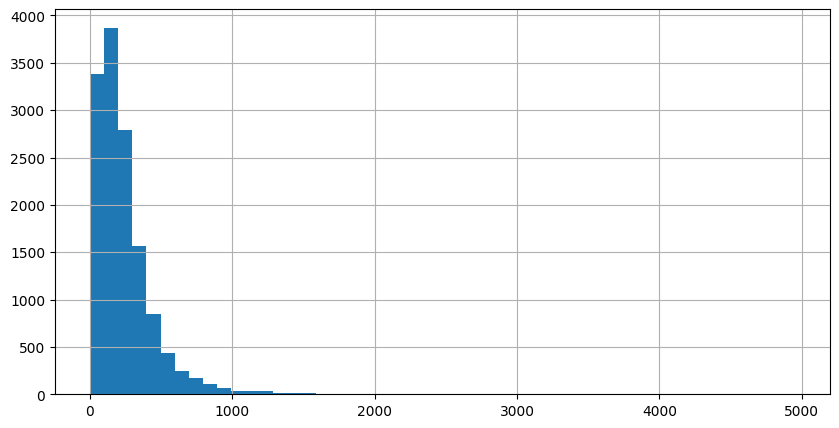

In [19]:
# Save the calculation to a variable instead of a column
word_counts = df['Consumer complaint narrative'].str.split().str.len()

# Plot the histogram directly from the variable
word_counts.hist(bins=50, figsize=(10, 5))

In [20]:
df["Issue"].value_counts().head(20)

,count
Issue,
Attempts to collect debt not owed,1758
Managing an account,1548
Problem with a purchase shown on your statement,897
False statements or representation,623
Written notification about debt,563
Incorrect information on your report,471
Trouble during payment process,436
Problem with a lender or other company charging your account,401
Fraud or scam,380


In [21]:
counts = df["Issue"].value_counts()

# keep only the 9 most frequent issues (the resume project used 9 categories)
TOP_N = 9
valid_labels = counts.head(TOP_N).index

df = df[df["Issue"].isin(valid_labels)]

# here we are basically keeping only the TOP_N most frequent issues
# (earlier version kept every issue with frequency >= 100, which gave ~35 hard, overlapping classes)

In [22]:
df['Issue'].nunique()

9

In [23]:
df.shape

(7077, 2)

In [24]:
counts.describe()

,count
count,86.000000
mean,159.209302
std,283.721368
min,1.000000
25%,9.250000
50%,59.000000
75%,194.250000
max,1758.000000


In [25]:
print("Samples:", len(df))
print("Classes:", df["Issue"].nunique())

df["Issue"].value_counts().describe()

Samples: 7077
Classes: 9


,count
count,9.000000
mean,786.333333
std,518.270200
min,380.000000
25%,436.000000
50%,563.000000
75%,897.000000
max,1758.000000


In [26]:
df= df.reset_index(drop=True, inplace=False) # reset indices after dropping a few rows
# inplace = True means that it return None

# Label Encoding

In [27]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["Issue"])

In [28]:
import pickle
# to save the encoder

In [29]:
with open ('label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

# we will be needing this later for our Streamlit app

# Train Test Split

In [30]:
df.shape

(7077, 3)

In [31]:
df.head()

,Issue,Consumer complaint narrative,label
0,Incorrect information on your report,This CFPB complaint has been filed to request ...,3
1,Incorrect information on your report,This CFPB complaint has been filed to request ...,3
2,Incorrect information on your report,This CFPB complaint has been filed to request ...,3
3,Incorrect information on your report,There were several attempts made since XXXX t...,3
4,Trouble during payment process,* * Summary of Missed Issues in Prior Complain...,7


In [32]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2,
                                     stratify=df["label"], # split according to df['label'] for even-ness
                                     random_state=42, shuffle=True)

In [33]:
train_df.shape

(5661, 3)

In [34]:
test_df.shape

(1416, 3)

# Making a validation split using train_df

In [35]:
train_df, val_df = train_test_split(
    train_df,
    test_size=0.1,
    stratify=train_df["label"],
    random_state=42
)

In [36]:
train_df.shape

(5094, 3)

In [37]:
val_df.shape

(567, 3)

# Converting into HF Dataset

We need this to train our datasets on transformer models. So hence we need to convert them to HF datasets

In [38]:
from datasets import Dataset

In [39]:
train_ds = Dataset.from_pandas(train_df.reset_index(drop=True))
val_ds   = Dataset.from_pandas(val_df.reset_index(drop=True))
test_ds= Dataset.from_pandas(test_df.reset_index(drop=True))

# as we splitted the df randomly into train_df and others
# the indices get randomly ordered
# so again reset index before converting into HF Dataset objects

# Tokenizing

In [40]:
from transformers import AutoTokenizer

model_name= 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [41]:
type(tokenizer)

transformers.models.bert.tokenization_bert.BertTokenizer

**AutoTokenizer** is a "factory class" provided by Hugging Face. It acts as an automatic identifier and downloader for text-processing rules.

Its use: It grabs the exact vocabulary dictionary and text-splitting logic associated with the specific model name you give it (in this case, "distilbert-base-uncased").

Why it is used (The main advantage):
Before AutoTokenizer existed, you had to manually memorize and import the exact Python class for every single model architecture. If you wanted to test three different models, your code looked like this

In [42]:
# defining tokenizing function
def tokenize(batch):
    return tokenizer(
        batch['Consumer complaint narrative'], #gives a list of complaint texts
        truncation=True, # cuts very long complaints to 256 tokens
        padding="max_length", # shorter complaints are padded to length 256
        max_length=256, # max token size of 256
    )

# tokenizing all the datasets
train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

# batch is a group of rows (sentences/complaints) that will be given as input
# we use batch over singular rows for faster processing

Map:   0%|          | 0/5094 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

Map:   0%|          | 0/1416 [00:00<?, ? examples/s]

In [43]:
train_ds.column_names
# HF Dataset way of showing cols

['Issue',
 'Consumer complaint narrative',
 'label',
 'input_ids',
 'token_type_ids',
 'attention_mask']

In [44]:
type(train_ds)

datasets.arrow_dataset.Dataset

# Removing columns

As now we have the tokens, along with their attention masks & input ids, we dont need the original data

In [45]:
# note: only drop the columns that actually exist (e.g. token_type_ids is not always produced)
cols_to_remove= ['Issue', 'Consumer complaint narrative', 'token_type_ids']
cols_to_remove= [c for c in cols_to_remove if c in train_ds.column_names]

train_ds= train_ds.remove_columns(cols_to_remove)
val_ds= val_ds.remove_columns(cols_to_remove)
test_ds= test_ds.remove_columns(cols_to_remove)

# Renaming "label" to "labels"

Hugging Face Trainer expects the target column to be named labels in most standard classification setups.  

If not renamed, the trainer may not automatically recognize it properly in some cases.

In [46]:
train_ds = train_ds.rename_column("label", "labels")
val_ds = val_ds.rename_column("label", "labels")
test_ds = test_ds.rename_column("label", "labels")

What each columns means:  

**abels** - Our target variable (for labelling the complaint)  

**input_ids** - This is the actual input to BERT.  
The complaint (say "Bad product") first gets tokenized (["Bad", "product"]) and then finally becomes an integer ([105,409]).  
These integers are basically called input_ids or **Word IDs**.  
Same tokens get same IDs.  

**attention_mask** - Often the complaint gets padded into a total of 256 tokens. This mask tells the model that (1- real token, 0- padding).  
So [204,102, 0, 0] gets masked into [1,1, 0, 0].  
Without this mask, BERT would think the padding is actual text.  
**input_ids are the indices used to look up the corresponding token embeddings in the embedding matrix.**

# Converting into Pytorch format  

Right now, dataset is still a HF Dataset containing Python lists.

DistilBERT, however, expects PyTorch tensors.

In [47]:
train_ds.column_names

['labels', 'input_ids', 'attention_mask']

In [48]:
train_ds.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

val_ds.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

test_ds.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

# .set_Format() converts py list into torch tensors

In [49]:
from datasets import config
config.TORCHVISION_AVAILABLE = False

print(type(train_ds[0]["input_ids"]))
print(type(train_ds[0]["attention_mask"]))
print(type(train_ds[0]["labels"]))

<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>


# Loading the model

In [50]:
from transformers import AutoModelForSequenceClassification

In [51]:
label_encoder.classes_
# all the classes in label encoder

array(['Attempts to collect debt not owed',
       'False statements or representation', 'Fraud or scam',
       'Incorrect information on your report', 'Managing an account',
       'Problem with a lender or other company charging your account',
       'Problem with a purchase shown on your statement',
       'Trouble during payment process',
       'Written notification about debt'], dtype=object)

In [52]:
num_labels = len(label_encoder.classes_)
# no. of labels

In [53]:
num_labels = len(label_encoder.classes_)

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=num_labels
)

# the above snippet of code is basically that we downloaded a pre trained DistilBERT model and added a classification head on top of it
# in this every token is a 768 dimensional vector (embedding)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [54]:
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

```
Complaint
      │
      ▼
Embedding
      │
      ▼
Transformer
      │
      ▼
768-dimensional vector
      │
      ▼
Linear Layer
      │
      ▼
35 logits
```  

**Logits** are the raw, unscaled, and unnormalized score outputs generated by the last layer of a machine learning or deep learning model before any activation function (like softmax or sigmoid) is applied. They represent the model's raw confidence for each possible choice or class.

Only this classifier is randomly initialized.

The rest comes from pretrained DistilBERT.

# Classification Metrics

In [55]:
!pip install evaluate

In [56]:
import evaluate
import numpy as np

In [57]:
accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

In [58]:
def compute(eval_preds): # evaluation predictions
  logits, labels= eval_preds

  predictions = np.argmax(logits, axis=-1)
  acc = accuracy.compute(predictions=predictions, references=labels)

  # multi-class, so we need an average (macro = every class counts equally)
  prec = precision.compute(predictions=predictions, references=labels, average="macro", zero_division=0)
  rec = recall.compute(predictions=predictions, references=labels, average="macro", zero_division=0)
  f1_score = f1.compute(predictions=predictions, references=labels, average="macro")

  # the Trainer needs a dict returned, otherwise it has no metrics to report
  return {
      "accuracy": acc["accuracy"],
      "precision": prec["precision"],
      "recall": rec["recall"],
      "f1": f1_score["f1"],
  }

# Here we write a function to find logits and get labels
# we put argmax on the logits to get the single highest value as our prediction
# then we compare prediction and labels

# Training config & Training

In [59]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results",              # where checkpoints and logs will go
    eval_strategy="epoch",               # run evaluation after each epoch
    save_strategy="epoch",               # save model after each epoch
    learning_rate=3e-5,                  # small learning rate for fine-tuning
    per_device_train_batch_size=8,       # start small because max_length=256
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    weight_decay=0.01,                   # small regularization
    logging_steps=50,                    # show training progress every 50 steps
    load_best_model_at_end=True,         # keep the best checkpoint
    metric_for_best_model="accuracy",     # since we kept accuracy as metric
    greater_is_better=True,
    fp16=torch.cuda.is_available(),      # use only if GPU is available (auto-detected; your last run was on CPU = very slow)
    report_to="none",                    # no wandb prompts
)

In [60]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute,
)

In [61]:
# Runtime > Change runtime type > GPU in Colab, otherwise this takes hours
print("GPU available:", torch.cuda.is_available())
trainer.train()

GPU available: True


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.097009,1.080752,0.590829,0.331156,0.454770,0.382643
2,0.855701,0.995363,0.619048,0.574664,0.555073,0.523407
3,0.674832,0.938285,0.668430,0.644398,0.611284,0.616394
4,0.565696,0.967087,0.657848,0.613093,0.617232,0.612348


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2548, training_loss=0.8697201752774943, metrics={'train_runtime': 227.0059, 'train_samples_per_second': 89.76, 'train_steps_per_second': 11.224, 'total_flos': 1349746332143616.0, 'train_loss': 0.8697201752774943, 'epoch': 4.0})

In [62]:
trainer.evaluate(test_ds)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.565696,0.851071,4,0.699859,0.675599,0.618584,0.631669


{'eval_loss': 0.8510705828666687,
 'eval_accuracy': 0.6998587570621468,
 'eval_precision': 0.6755994876467855,
 'eval_recall': 0.6185842305325104,
 'eval_f1': 0.6316686290535949}

# Detailed per-class report

In [63]:
from sklearn.metrics import classification_report

pred_output = trainer.predict(test_ds)
y_pred = np.argmax(pred_output.predictions, axis=-1)
y_true = pred_output.label_ids

print(classification_report(y_true, y_pred, labels=range(num_labels),
                            target_names=label_encoder.classes_, zero_division=0))

                                                              precision    recall  f1-score   support

                           Attempts to collect debt not owed       0.66      0.86      0.75       352
                          False statements or representation       0.59      0.38      0.47       125
                                               Fraud or scam       0.68      0.57      0.62        76
                        Incorrect information on your report       0.65      0.67      0.66        94
                                         Managing an account       0.74      0.82      0.78       310
Problem with a lender or other company charging your account       0.42      0.24      0.30        80
             Problem with a purchase shown on your statement       0.77      0.84      0.80       179
                              Trouble during payment process       0.92      0.91      0.91        87
                             Written notification about debt       0.64      0.28

# Saving the model

We will load these later in our Streamlit app (along with label_encoder.pkl)

In [64]:
trainer.save_model("./complaint_model")
tokenizer.save_pretrained("./complaint_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./complaint_model/tokenizer_config.json', './complaint_model/tokenizer.json')

# Inference on a new complaint

In [65]:
from transformers import pipeline

clf = pipeline("text-classification", model="./complaint_model", tokenizer="./complaint_model",
               device=0 if torch.cuda.is_available() else -1, top_k=3,
               truncation=True, max_length=256)

def predict_issue(text):
    results = clf(text)[0]  # top 3 predictions
    # the pipeline returns labels like 'LABEL_12' -> convert back to the real Issue name
    return [(label_encoder.inverse_transform([int(r["label"].split("_")[1])])[0], round(r["score"], 3))
            for r in results]

predict_issue("I keep getting calls from a debt collector for a debt that is not mine.")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[('Attempts to collect debt not owed', 0.779),
 ('Written notification about debt', 0.152),
 ('False statements or representation', 0.053)]

# Saving the Model

In [66]:
# import shutil
# from google.colab import files

# shutil.copy("label_encoder.pkl", "complaint_model/label_encoder.pkl")  # label names for the API
# shutil.make_archive("complaint_model", "zip", "complaint_model")
# files.download("complaint_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
# print("Download done")

Download done
